# Mustafa Abbas Abokhadher
# 2240002889
# 7MA2

Image size: (400, 600, 3)


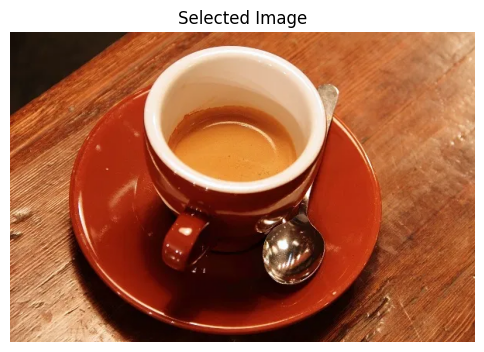

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'coffee.jpg'

img = cv2.imread(imgFile)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
print("Image size:", img.shape)

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.title('Selected Image'); plt.axis('off')
plt.show()

### 1) Sobel Edge Detector

In [2]:
sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_combined = cv2.magnitude(sobelx, sobely)
sobel_final = np.uint8(np.clip(sobel_combined, 0, 255))

### 2) Prewitt Edge Detector

In [3]:
kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)

prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)
prewitt_combined = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_final = np.uint8(np.clip(prewitt_combined, 0, 255))

### 3) Canny Edge Detector

In [4]:
canny_edges = cv2.Canny(blurred, 100, 200)

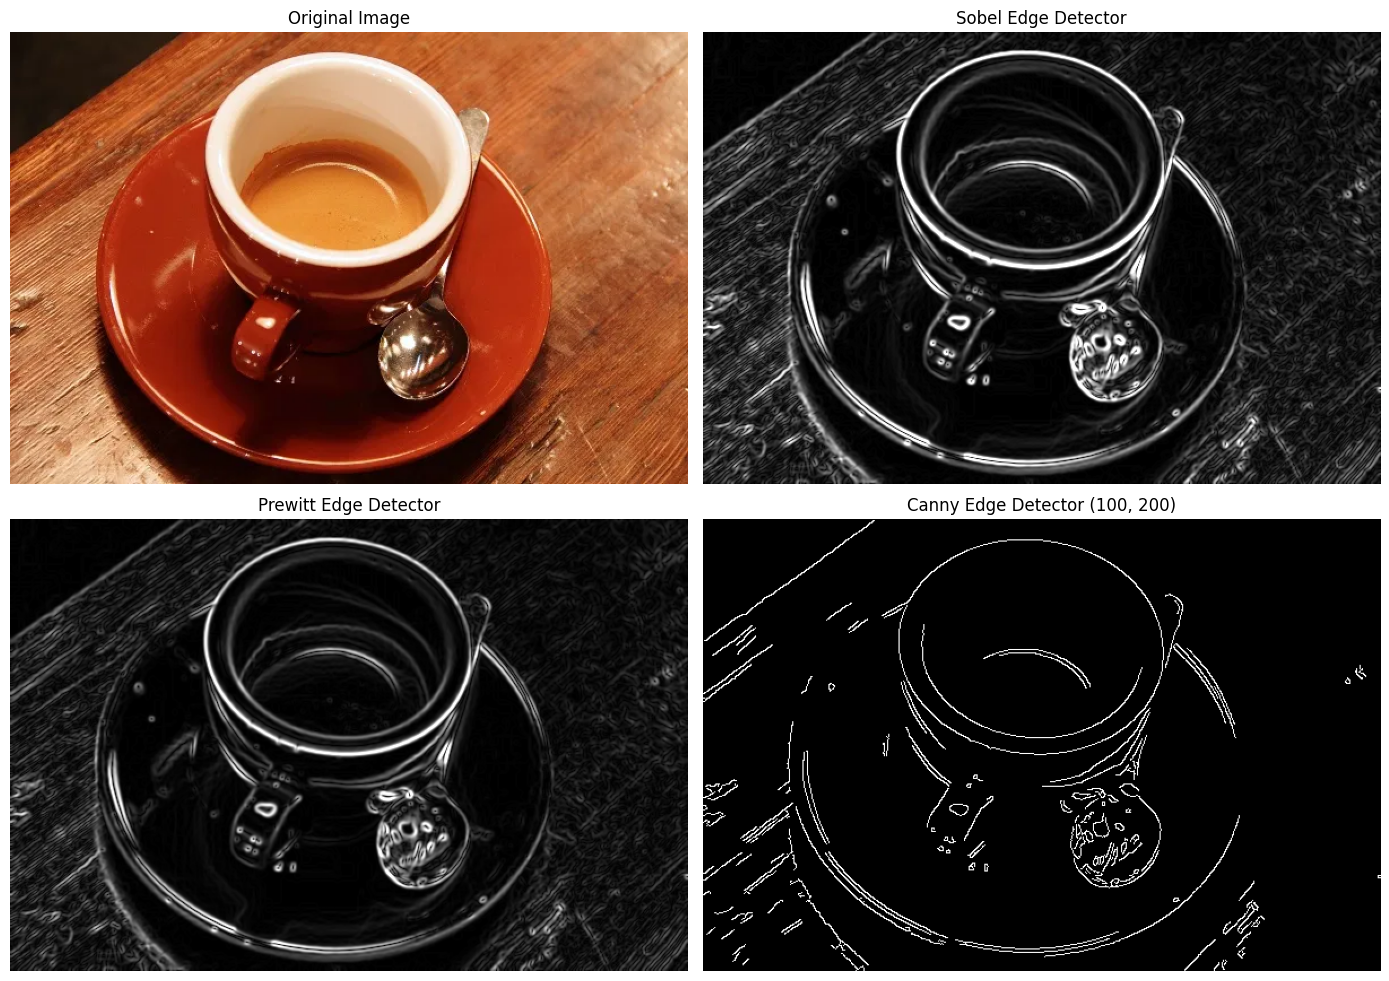

In [5]:
plt.figure(figsize=(14, 10))
plt.subplot(2, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Image')
plt.subplot(2, 2, 2), plt.imshow(sobel_final, cmap='gray'),   plt.title('Sobel Edge Detector')
plt.subplot(2, 2, 3), plt.imshow(prewitt_final, cmap='gray'), plt.title('Prewitt Edge Detector')
plt.subplot(2, 2, 4), plt.imshow(canny_edges, cmap='gray'),   plt.title('Canny Edge Detector (100, 200)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

**Comparison:** Sobel and Prewitt are gradient-magnitude operators; their output is a grey-level map with thick edges (strong edges bright, weak edges dim). Sobel gives more weight to the centre row/column, so it smooths slightly more and is a little less noisy than Prewitt. Canny gives thin (1-pixel), clean, binary edges because it adds non-maximum suppression and hysteresis thresholding.

## Task 2: Effect of Canny Thresholds

Low= 30, High= 90 -> edge pixels =  41943  (17.48 % of the image)
Low= 50, High=150 -> edge pixels =  31154  (12.98 % of the image)
Low=100, High=200 -> edge pixels =  20046  (8.35 % of the image)


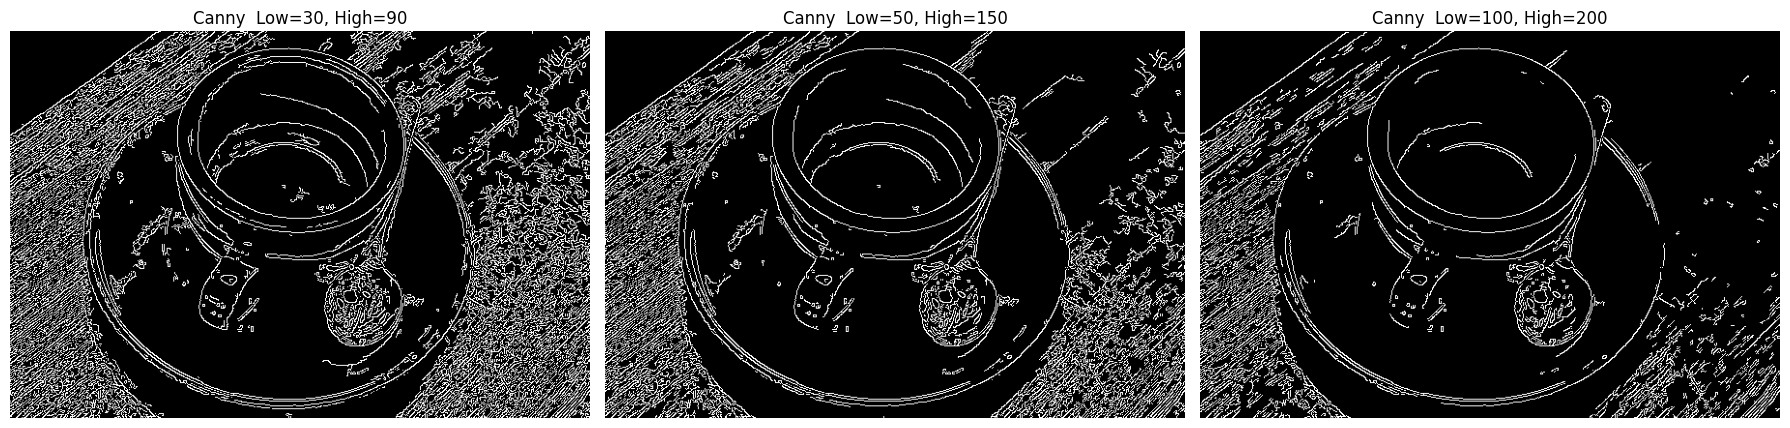

In [6]:
thresholds = [(30, 90), (50, 150), (100, 200)]
results = []
for low, high in thresholds:
    e = cv2.Canny(gray, low, high)
    results.append(e)
    print(f"Low={low:3d}, High={high:3d} -> edge pixels = {np.count_nonzero(e):6d}  ({100*np.count_nonzero(e)/e.size:.2f} % of the image)")

plt.figure(figsize=(18, 6))
for i, ((low, high), e) in enumerate(zip(thresholds, results)):
    plt.subplot(1, 3, i + 1), plt.imshow(e, cmap='gray'), plt.title(f'Canny  Low={low}, High={high}'), plt.axis('off')
plt.tight_layout()
plt.show()

### Explanation
(see the printed edge-pixel counts above)

Canny uses two thresholds (hysteresis): pixels with gradient **above High** are *strong* edges and always kept; pixels **below Low** are discarded; pixels **between Low and High** are kept only if they are connected to a strong edge.

* **Low = 30, High = 90 (low thresholds):** the most edges are detected. Fine details, texture and weak/noisy edges (e.g. the surface texture and small intensity changes) appear, so the map is cluttered and may contain false edges.
* **Low = 50, High = 150 (medium):** a balanced result – the main object outlines and important details are kept while a lot of the weak texture/noise disappears.
* **Low = 100, High = 200 (high thresholds):** the fewest edges; only strong, high-contrast boundaries survive. The result is clean but small details and low-contrast edges are lost and some outlines can break.

**Conclusion:** increasing the thresholds → fewer detected edges, less noise, but less visible detail; decreasing them → more edges and more detail, but also more noise/false edges. The thresholds must be chosen according to the image contrast and the application (a 1:2 or 1:3 Low:High ratio is a good rule of thumb).